<a href="https://colab.research.google.com/github/mahdisahad/WOA-Feature-Selection/blob/main/notebooks/01_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install numpy pandas scikit-learn matplotlib scipy

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/WOA_Project"
)

import sys
sys.path.append(str(PROJECT_PATH))
from dataset_config import *   # <-- dataset-specific code lives only here
print("Active dataset:", ACTIVE_DATASET)

NOTEBOOK_PATH = PROJECT_PATH / "notebooks"

RESULTS_PATH = PROJECT_PATH / "results"

print("Project exists:", PROJECT_PATH.exists())
print("Datasets folder exists:", (PROJECT_PATH / "datasets").exists())
print("Notebooks exists:", NOTEBOOK_PATH.exists())
print("Results exists:", RESULTS_PATH.exists())

Active dataset: parkinson
Project exists: True
Datasets folder exists: True
Notebooks exists: True
Results exists: True


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
# Load the active dataset (path/format handled by dataset_config.py)
df = load_dataset(PROJECT_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (756, 755)


,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,locAbsJitter,...,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,group,class
0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,0.000018,...,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,0,1
1,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,0.000016,...,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,0,1
2,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,0.000015,...,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,0,1
3,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,0.000046,...,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1,1
4,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,0.000044,...,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1,1


In [6]:
# اینجا یه ارور بود که مسیر رو فایل تنظیم نشده بود رو فولدر بوده
import os

DATASETS_PATH = PROJECT_PATH / "datasets"

for root, dirs, files in os.walk(DATASETS_PATH):
    print(f"\nFolder: {root}")

    for file in files:
        print("File:", file)


Folder: /content/drive/MyDrive/WOA_Project/datasets
File: colon_dataset.csv

Folder: /content/drive/MyDrive/WOA_Project/datasets/colon
File: colon_dataset.arff
File: colon_dataset.csv

Folder: /content/drive/MyDrive/WOA_Project/datasets/bc
File: wdbc.data
File: wdbc.names

Folder: /content/drive/MyDrive/WOA_Project/datasets/pk
File: pd_speech_features.csv

Folder: /content/drive/MyDrive/WOA_Project/datasets/tcga
File: data.csv
File: labels.csv


In [7]:
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1 - ("group" in df.columns))
print("Target column: class")
print("Dataset shape:", df.shape)

Number of samples: 756
Number of features: 753
Target column: class
Dataset shape: (756, 755)


In [8]:
X, y, groups = split_xy(df)
y = y.astype(str)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 labels:")
print(y.head())

Features shape: (756, 753)
Target shape: (756,)

First 5 labels:
0    1
1    1
2    1
3    1
4    1
Name: class, dtype: object


In [9]:
class_counts = y.value_counts()

print(class_counts)

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

class
1    564
0    192
Name: count, dtype: int64

Class percentages:
class
1    74.603175
0    25.396825
Name: proportion, dtype: float64


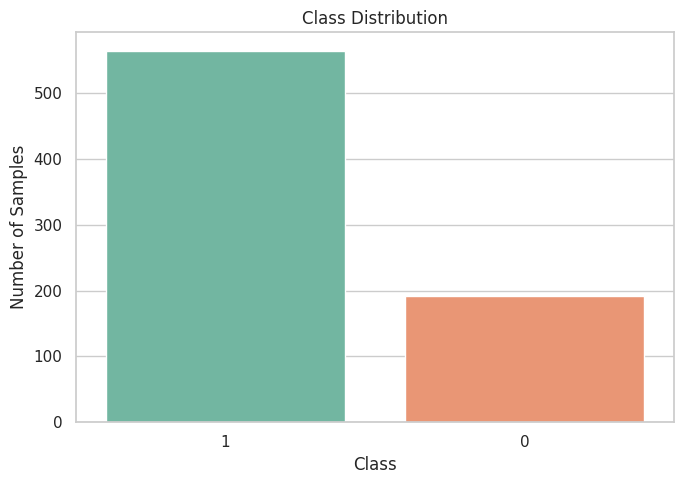

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [11]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [12]:
print(df.dtypes.value_counts())

print("\nTarget data type:")
print(df["class"].dtype)

float64    749
int64        6
Name: count, dtype: int64

Target data type:
int64


In [13]:
constant_features = X.columns[
    X.nunique() <= 1
]

print("Number of constant features:", len(constant_features))

print("Constant feature names:")
print(list(constant_features))

Number of constant features: 0
Constant feature names:
[]


In [14]:
duplicate_features = X.columns[
    X.T.duplicated()
]

print("Number of duplicate features:", len(duplicate_features))

print("Duplicate feature names:")
print(list(duplicate_features))

Number of duplicate features: 0
Duplicate feature names:
[]


In [15]:
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
gender,756.0,0.515873,0.500079,0.000000,0.000000,1.000000,1.000000,1.00000
PPE,756.0,0.746284,0.169294,0.041551,0.762833,0.809655,0.834315,0.90766
DFA,756.0,0.700414,0.069718,0.543500,0.647053,0.700525,0.754985,0.85264
RPDE,756.0,0.489058,0.137442,0.154300,0.386537,0.484355,0.586515,0.87123
numPulses,756.0,323.972222,99.219059,2.000000,251.000000,317.000000,384.250000,907.00000
...,...,...,...,...,...,...,...,...
tqwt_kurtosisValue_dec_32,756.0,12.218953,17.783642,1.789500,2.937025,4.300450,10.876150,85.57170
tqwt_kurtosisValue_dec_33,756.0,12.375335,16.341665,1.628700,3.114375,4.741450,12.201325,73.53220
tqwt_kurtosisValue_dec_34,756.0,14.799230,15.722502,1.861700,3.665925,6.725700,21.922050,62.00730
tqwt_kurtosisValue_dec_35,756.0,14.751559,14.432979,1.955900,3.741275,7.334250,22.495175,57.54430


In [16]:
print("Mean of feature means:", X.mean().mean())

print("Mean of feature standard deviations:", X.std().mean())

print("Minimum value:", X.min().min())

print("Maximum value:", X.max().max())

Mean of feature means: -23668440.911655985
Mean of feature standard deviations: 15074129.855129045
Minimum value: -62062235037.0
Maximum value: 74325483.41


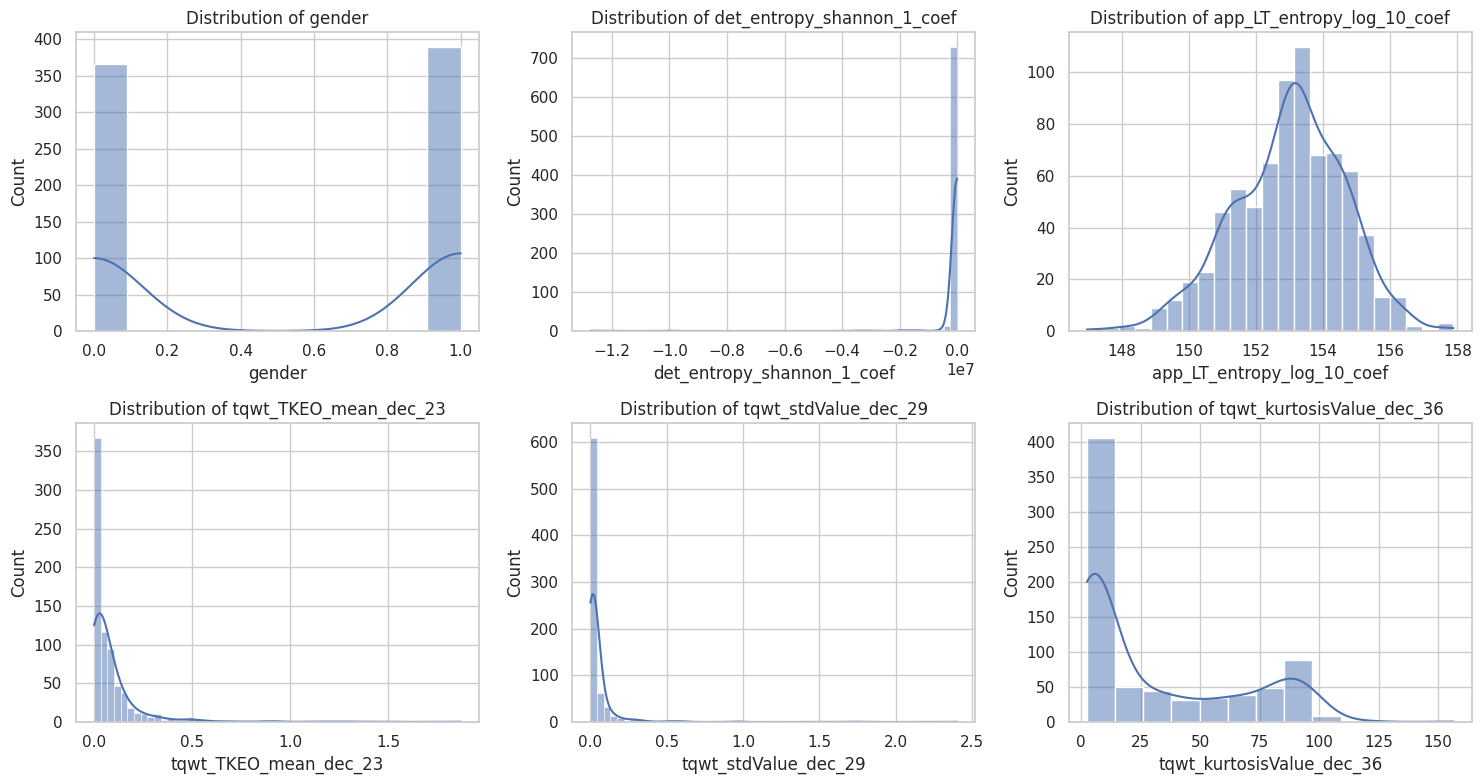

In [17]:
selected_features = [X.columns[i] for i in np.linspace(0, X.shape[1] - 1, 6).astype(int)]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

for ax, feature in zip(axes.flatten(), selected_features):

    sns.histplot(
        X[feature],
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

In [18]:
OUTPUT_PATH = PROJECT_PATH / "datasets" / f"{ACTIVE_DATASET}_dataset.csv"

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("CSV file saved successfully!")
print("Saved at:", OUTPUT_PATH)

CSV file saved successfully!
Saved at: /content/drive/MyDrive/WOA_Project/datasets/parkinson_dataset.csv


In [19]:
CSV_PATH = PROJECT_PATH / "datasets" / f"{ACTIVE_DATASET}_dataset.csv"

df.to_csv(CSV_PATH, index=False)

print("Dataset saved successfully!")
print("Saved path:", CSV_PATH)
print("Dataset shape:", df.shape)

Dataset saved successfully!
Saved path: /content/drive/MyDrive/WOA_Project/datasets/parkinson_dataset.csv
Dataset shape: (756, 755)


In [20]:
import pandas as pd

df_check = pd.read_csv(CSV_PATH)

print("Loaded shape:", df_check.shape)
print("Original shape:", df.shape)
print("File exists:", CSV_PATH.exists())

Loaded shape: (756, 755)
Original shape: (756, 755)
File exists: True
